In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from ActivityPipelines import split_activity_data, ActivityLoader
from DistanceProject import DistanceStimulusLoader, DistanceAnalysis, create_new_result_dir
from DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os
from matplotlib.backends.backend_pdf import PdfPages
import random
from pathlib import Path

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'

In [2]:
imaging_filenames = [r'240731_SAM019_1']

results_directories = []
for imaging_filename in imaging_filenames:
    results_directories.append(data_dir + '/' + str(imaging_filename) + '/results')

In [3]:
Data = []
for imaging_filename in imaging_filenames:

    imaging_dir = os.path.join(data_dir, imaging_filename)

    # create folder
    results_dir = create_new_result_dir(imaging_dir, 'results')

    D = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='dFF')
    
    if np.shape(D.distance_mat)[0] == 144:
        D.one_eye = np.array([np.arange(0, 36, 1), np.arange(72, 108, 1)])
        D.two_eye = np.array([np.arange(36, 72, 1), np.arange(108, 144, 1)])
    elif np.shape(D.distance_mat)[0] == 180:
        D.one_eye = np.array([np.arange(0, 45, 1), np.arange(90, 135, 1)])
        D.two_eye = np.array([np.arange(45, 90, 1), np.arange(135, 180, 1)])
    
    D.identify_missed_repeats()
    Data.append(D)

Directory results already exists


In [6]:
cell = 2
is_active, distance = D.is_active(cell = cell, block='two eye')
is_reliable, reliability, corr_shifted = D.compute_reliability(cell = cell, block='two eye')
print(is_active)
print(is_reliable)
print(distance)

True
9.090909090909093
True
True
9.090909090909093


In [10]:
is_reliable_one_all = []
is_reliable_two_all = []

reliability_one_all = []
reliability_two_all = []

for i, D in enumerate(Data):
    
    print('Session being analyzed ', imaging_filenames[i])

    is_reliable_one, reliability_one = D.compute_reliability_all_cells(block='two eye', n_iterations = 200)
    print('Reliability one eye done')
    is_reliable_two, reliability_two = D.compute_reliability_all_cells(block='two eye', n_iterations = 200)
    print('Reliability two eye done')

    is_reliable_one_all.append(is_reliable_one)
    is_reliable_two_all.append(is_reliable_two)

    reliability_one_all.append(reliability_one)
    reliability_two_all.append(reliability_two)
  

Session being analyzed  240731_SAM019_1
 Cell 616Reliability one eye done
 Cell 616Reliability two eye done


In [18]:
D.stats['is_reliable_one_eye']

KeyError: 'is_reliable_one_eye'

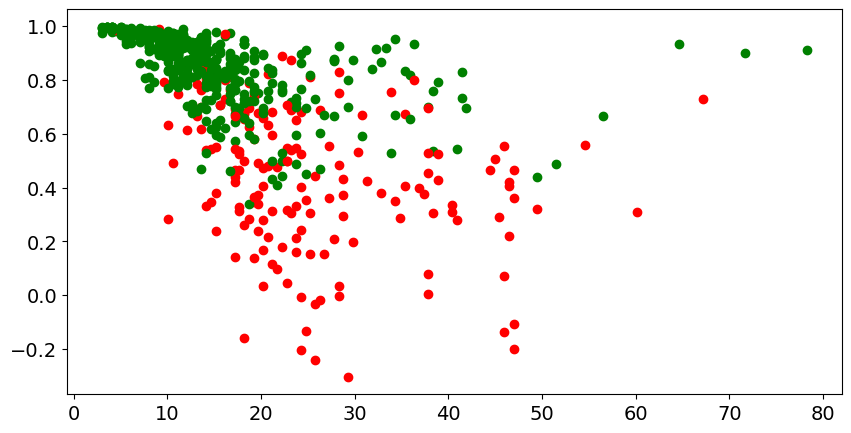

In [65]:
plt.figure(figsize=(10, 5))
for distance, value, is_rel in zip(median_distance, reliability, is_reliable):
    
    if is_rel:
        plt.scatter(distance, value, color='green')
    else:
        plt.scatter(distance, value, color='red')
        

In [99]:
cell = 92
print(median_distance[cell])
print(reliability[cell])

13.131313131313135
0.912929222922639


KeyError: 'is_reliable_one_eye'

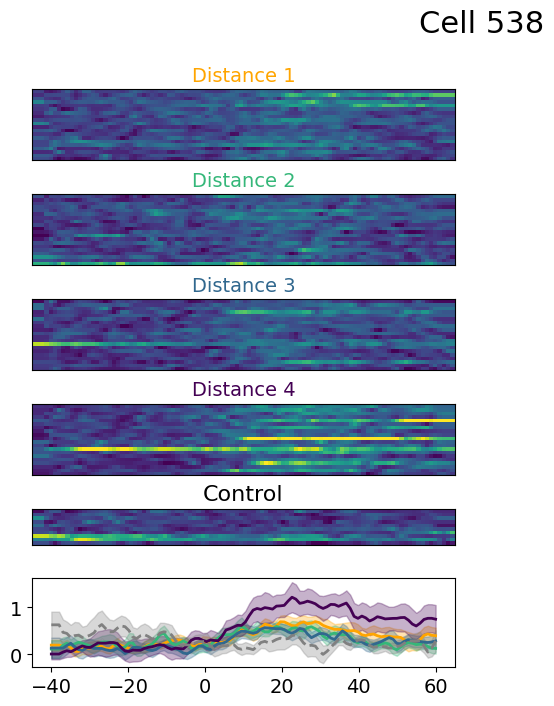

In [100]:
plot_trials_ordered_2(D, cell = 538)

Reliability:  0.9169853945215525
Max correlation:  0.6845450169521308
46.25
10.606060606060609


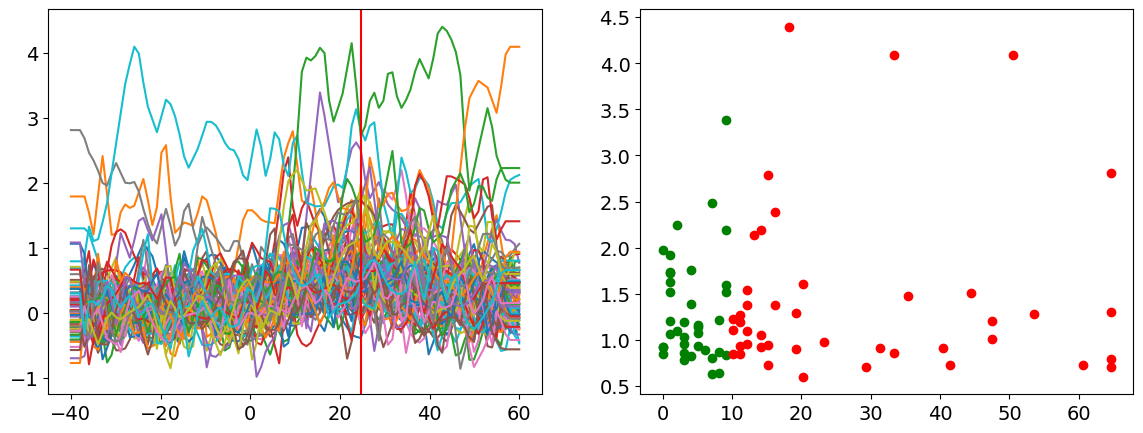

In [56]:
cell = 538
block = 'one eye'

is_reliable, reliability, corr_shifted = D.compute_reliability(cell = cell, block=block)
receptive_field = D.compute_receptive_field(cell, block=block)
print('Reliability: ', reliability)
print('Max correlation: ', np.max(corr_shifted))

all_traces = D.get_all_traces(cell, distance=[1, 2, 3, 4], block=block)

plt.subplots(1, 2, figsize=(14, 5))

ax1 = plt.subplot(121)

max_value = []
where_max = []
for trace in all_traces:
    max_value.append(np.max(trace))
    where_max.append(D.angle_range[np.argmax(trace)])
    ax1.plot(D.angle_range, trace)
# calculate the absolute distance to the receptive field
where_max = np.array(where_max)
where_dist = np.abs(where_max - D.angle_range[receptive_field])

ax1.axvline(D.angle_range[receptive_field], color='red')

ax2 = plt.subplot(122)

for distance, value in zip(where_dist, max_value):
    
    if distance < 10:
        ax2.scatter(distance, value, color='green')
        
    else:
        ax2.scatter(distance, value, color='red')
        
print(np.median(where_dist))

In [ ]:
is_reliable_one_all = []
is_reliable_two_all = []

reliability_one_all = []
reliability_two_all = []

for i, D in enumerate(Data):
    
    print('Session being analyzed ', imaging_filenames[i])

    is_reliable_one, reliability_one = D.compute_reliability_all_cells(block='one eye', n_iterations = 50)
    print('Reliability one eye done')
    is_reliable_two, reliability_two = D.compute_reliability_all_cells(block='two eye', n_iterations = 50)
    print('Reliability two eye done')

    is_reliable_one_all.append(is_reliable_one)
    is_reliable_two_all.append(is_reliable_two)

    reliability_one_all.append(reliability_one)
    reliability_two_all.append(reliability_two)

Session being analyzed  240731_SAM019_1
 Cell 228

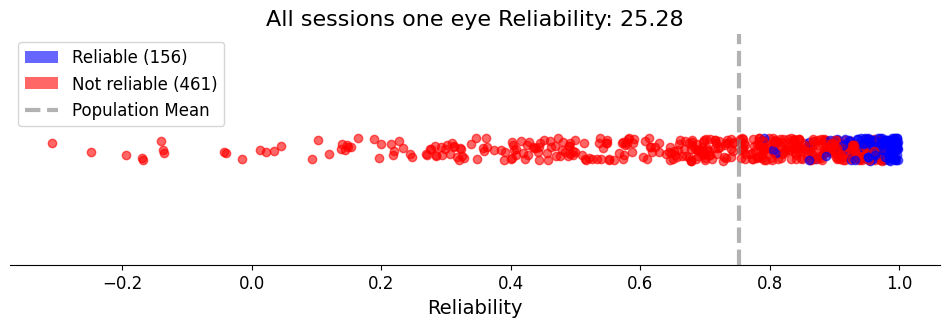

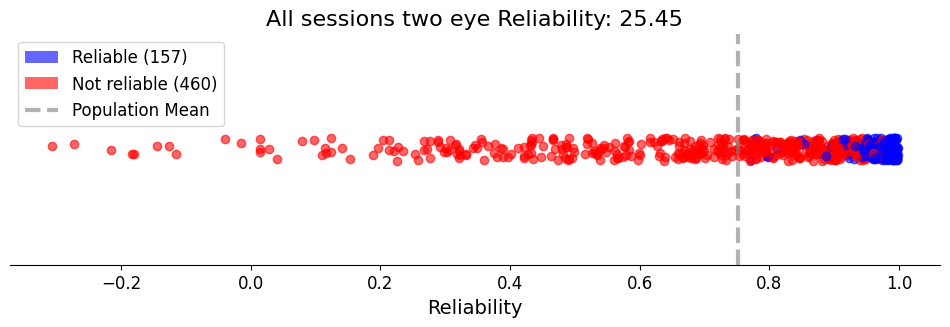

In [11]:
# concatenate all the is_reliable and reliability into one array
plot_reliability_distribution(np.concatenate(is_reliable_one_all), np.concatenate(reliability_one_all), title='All sessions one eye')
plot_reliability_distribution(np.concatenate(is_reliable_two_all), np.concatenate(reliability_two_all), title='All sessions two eye')

In [15]:
for D in Data:
    D.compute_distance_modulation_all_cells(block='one eye')
    D.compute_distance_modulation_all_cells(block='two eye')

KeyError: 'is_reliable_one_eye'

In [17]:
D.stats['is_reliable_one_eye']

KeyError: 'is_reliable_one_eye'

In [10]:
results_directories = data_dir + '/' + str(imaging_filenames[0]) + '/results'

for i, D in enumerate(Data):

    monocular_count = 0
    binocular_count = 0
    monocular_binocular_count = 0
    not_modulated_count = 0

    reliable_cells = np.where(np.logical_or(D.stats['is_reliable_one_eye'], D.stats['is_reliable_two_eye']))[0]

    monocular_dir = create_new_result_dir(results_directories, 'monocular_modulated_dFF')
    binocular_dir = create_new_result_dir(results_directories, 'binocular_modulated_dFF')
    monocular_and_binocular_dir = create_new_result_dir(results_directories, 'monocular_binocular_modulated_dFF')
    not_modulated_dir = create_new_result_dir(results_directories, 'not_modulated_dFF')

    for cell in reliable_cells:

        is_monocular_modulated, _, _ = D.compute_distance_modulation(cell, block='one eye')
        is_binocular_modulated, _, _ = D.compute_distance_modulation(cell, block='two eye')

        if is_binocular_modulated and is_monocular_modulated:
            monocular_binocular_count += 1
            plot_trials_ordered_2(D, cell=cell, title=imaging_filenames[i])
            plt.savefig(os.path.join(monocular_and_binocular_dir, imaging_filenames[i] + f'_{cell}.png'))
            plt.close()

        elif is_monocular_modulated:
            monocular_count += 1
            plot_trials_ordered_2(D, cell=cell, title=imaging_filenames[i])
            plt.savefig(os.path.join(monocular_dir, imaging_filenames[i] + f'_{cell}.png'))
            plt.close()

        elif is_binocular_modulated:
            binocular_count += 1
            plot_trials_ordered_2(D, cell=cell, title=imaging_filenames[i])
            plt.savefig(os.path.join(binocular_dir, imaging_filenames[i] + f'_{cell}.png'))
            plt.close()

        else:
            not_modulated_count += 1
            plot_trials_ordered_2(D, cell=cell, title=imaging_filenames[i])
            plt.savefig(os.path.join(not_modulated_dir, imaging_filenames[i] + f'_{cell}.png'))
            plt.close()

    print('Monocular modulated: ', monocular_count)
    print('Binocular modulated: ', binocular_count)
    print('Monocular and Binocular modulated: ', monocular_binocular_count)
    print('Not modulated: ', not_modulated_count)

    # make pie plot of the counts
    plt.figure()
    labels = ['Monocular', 'Binocular', 'Monocular and Binocular', 'Not modulated']
    sizes = [monocular_count, binocular_count, monocular_binocular_count, not_modulated_count]
    colors = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue']
    explode = (0.1, 0, 0, 0)

    plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
    # set title
    plt.title(D.path)
    plt.savefig(os.path.join(results_directories, 'modulation_pie_dFF.png'))
    plt.close()
    plt.close()

Creating directory: monocular_modulated_dFF
Creating directory: binocular_modulated_dFF
Creating directory: monocular_binocular_modulated_dFF
Creating directory: not_modulated_dFF
Monocular modulated:  8
Binocular modulated:  22
Monocular and Binocular modulated:  1
Not modulated:  233


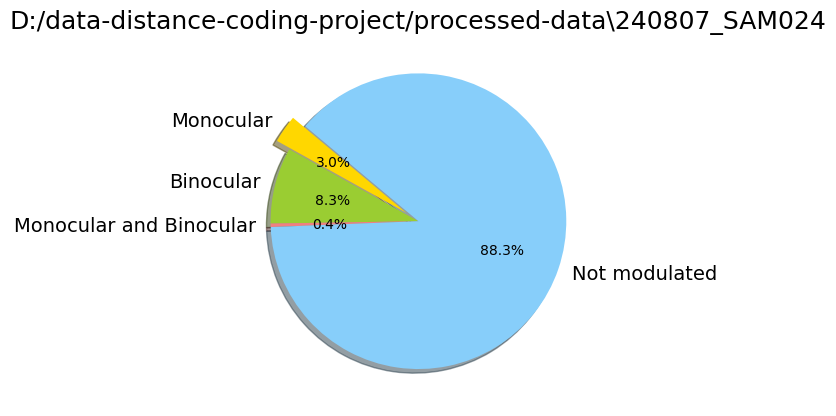

In [11]:
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
# set title
plt.title(D.path)
plt.savefig(os.path.join(results_directories, 'modulation_pie.png'))

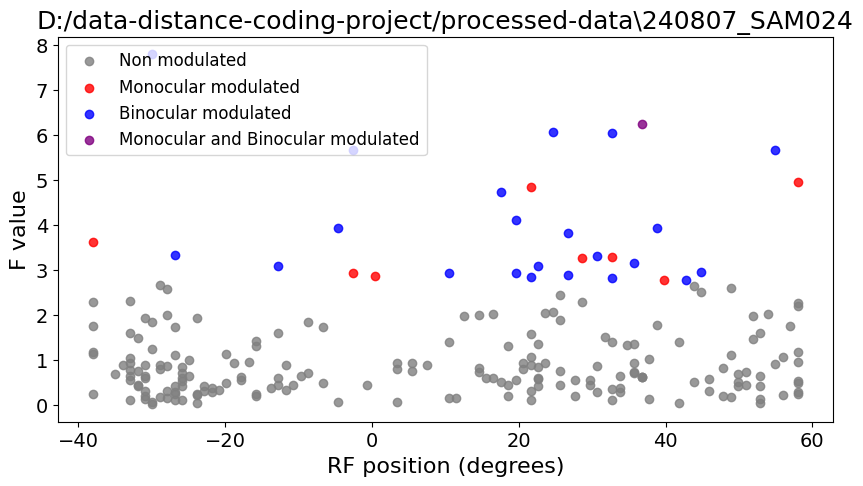

In [12]:
for D in Data:
    
    RF = []
    monocular_rho = []
    binocular_rho = []
    monocular_F = []
    binocular_F = []
    
    reliable_cells = np.where(np.logical_or(D.stats['is_reliable_one_eye'], D.stats['is_reliable_two_eye']))[0]
    
    for cell in reliable_cells:
        
        if D.stats['is_reliable_one_eye'][cell] and D.stats['is_reliable_two_eye'][cell]:
            RF.append(D.angle_range[D.compute_receptive_field(cell)])
        elif D.stats['is_modulated_one_eye'][cell]:
            RF.append(D.angle_range[D.compute_receptive_field(cell, block='one eye')])
        else: 
            RF.append(D.angle_range[D.compute_receptive_field(cell, block='two eye')])
        
        is_monocular_modulated, one_eye_rho, one_eye_F = D.compute_distance_modulation(cell, block='one eye')
        is_binocular_modulated, two_eye_rho, two_eye_F = D.compute_distance_modulation(cell, block='two eye')
        
        monocular_rho = np.append(monocular_rho, one_eye_rho)
        binocular_rho = np.append(binocular_rho, two_eye_rho)
        monocular_F = np.append(monocular_F, one_eye_F)
        binocular_F = np.append(binocular_F, two_eye_F)        
        
    # get the RF of the non_modulated_cells
    non_modulated_cells = np.logical_and(monocular_rho>0.05, binocular_rho>0.05)
    monocular_modulated = np.logical_and(monocular_rho<0.05, binocular_rho>0.05)
    binocular_modulated = np.logical_and(monocular_rho>0.05, binocular_rho<0.05)
    monocular_binocular_modulated = np.logical_and(monocular_rho<0.05, binocular_rho<0.05)
    
    # Select the F indices where non_modulated_cells is true
    F_non_modulated = monocular_F[non_modulated_cells]
    RF_non_modulated = np.array(RF)[non_modulated_cells]
    
    # monocular modulated
    F_monocular = monocular_F[monocular_modulated]
    RF_monocular = np.array(RF)[monocular_modulated]
    
    # binocular modulated
    F_binocular = binocular_F[binocular_modulated]
    RF_binocular = np.array(RF)[binocular_modulated]
    
    # monocular and binocular modulated
    F_monocular_binocular = (binocular_F[monocular_binocular_modulated] + monocular_F[monocular_binocular_modulated])/2
    RF_monocular_binocular = np.array(RF)[monocular_binocular_modulated]
    
    plt.figure(figsize=(10, 5))
    
    plt.scatter(RF_non_modulated, F_non_modulated, color = 'gray', label = 'Non modulated', alpha=0.8)
    plt.scatter(RF_monocular, F_monocular, color = 'red', label = 'Monocular modulated', alpha=0.8)
    plt.scatter(RF_binocular, F_binocular, color = 'blue', label = 'Binocular modulated', alpha = 0.8)
    plt.scatter(RF_monocular_binocular, F_monocular_binocular, color = 'purple', label = 'Monocular and Binocular modulated', alpha = 0.8)
    plt.xlabel('RF position (degrees)', fontsize = 16)
    plt.ylabel('F value', fontsize = 16)
    plt.title(D.path)
    plt.legend()
    plt.savefig(os.path.join(results_directories, 'RF_vs_modulation_dFF.png'))
    

# Experimental stuff
Things I want to have:
- Plot all cells by order of reliability
- Plot all cells by order of trials (without control trials, see if there is drift)
- Get to plot stats on the map, with the cells colored by those stats

## Plot all cells by order of reliability

In [513]:
print(results_directories)
print(imaging_filenames[0])

D:/data-distance-coding-project/processed-data/240802_SAM024/results
240802_SAM024


In [514]:
for i, D in enumerate(Data):
    
    reliability_dir = create_new_result_dir(results_directories, 'reliability')
    modulation_dir = create_new_result_dir(results_directories, 'modulation')
    
    D.compute_reliability_all_cells(n_iterations = 50, block = 'one eye')
    D.compute_reliability_all_cells(n_iterations = 50, block = 'two eye')

    reliability_one_eye = D.stats['reliability_one_eye']
    reliability_two_eye = D.stats['reliability_two_eye']

    # for every value of reliability_one_eye, reliability_two_eye, pick the highest
    reliability = np.maximum(reliability_one_eye, reliability_two_eye)
    order_reliability = np.argsort(reliability)[::-1]

    # plot the cells by order of reliability
    for cell in order_reliability:
        print('\r Cell ' + str(cell), end="")

        all_traces = D.get_all_traces(cell, distance = [1, 2 ,3 , 4], mean_trace = False)
        all_traces_mean = np.mean(all_traces, axis=0)

        max_index = np.argmax(all_traces_mean)
        receptive_pos = D.angle_range[max_index]
        # get values at the receptive pos for all the traces
        values = []
        for trace in all_traces:
            values.append(trace[max_index])

        plot_trials(D, cell = cell, title = r'$\sigma$ = ' + str(round(np.median(values), 3)))

        # plt.savefig(os.path.join(reliability_dir, imaging_filenames[i] + f'_{cell}.png'))
        # 
        # 
        # plot_trials_ordered_2(D, cell = cell)
        # plt.savefig(os.path.join(modulation_dir, imaging_filenames[i] + f'_{cell}.png'))
        

Directory reliability already exists
Directory modulation already exists
 Cell 28

KeyboardInterrupt: 

In [525]:
# D.compute_reliability_all_cells(n_iterations = 50, block = 'one eye')
# D.compute_reliability_all_cells(n_iterations = 50, block = 'two eye')

reliability_one_eye = D.stats['reliability_one_eye']
reliability_two_eye = D.stats['reliability_two_eye']

reliability = np.maximum(reliability_one_eye, reliability_two_eye)
order_reliability = np.argsort(reliability)[::-1]
reliability_dir = create_new_result_dir(results_directories, 'reliability')
modulation_dir = create_new_result_dir(results_directories, 'modulation')

for cell in order_reliability:
    print('\r Cell ' + str(cell), end="")
    
    plot_trials_ordered_2(D, cell = cell)
    plt.savefig(os.path.join(modulation_dir, imaging_filenames[0] + f'_{cell}.png'))
    plt.close()

Directory reliability already exists
Directory modulation already exists
 Cell 118

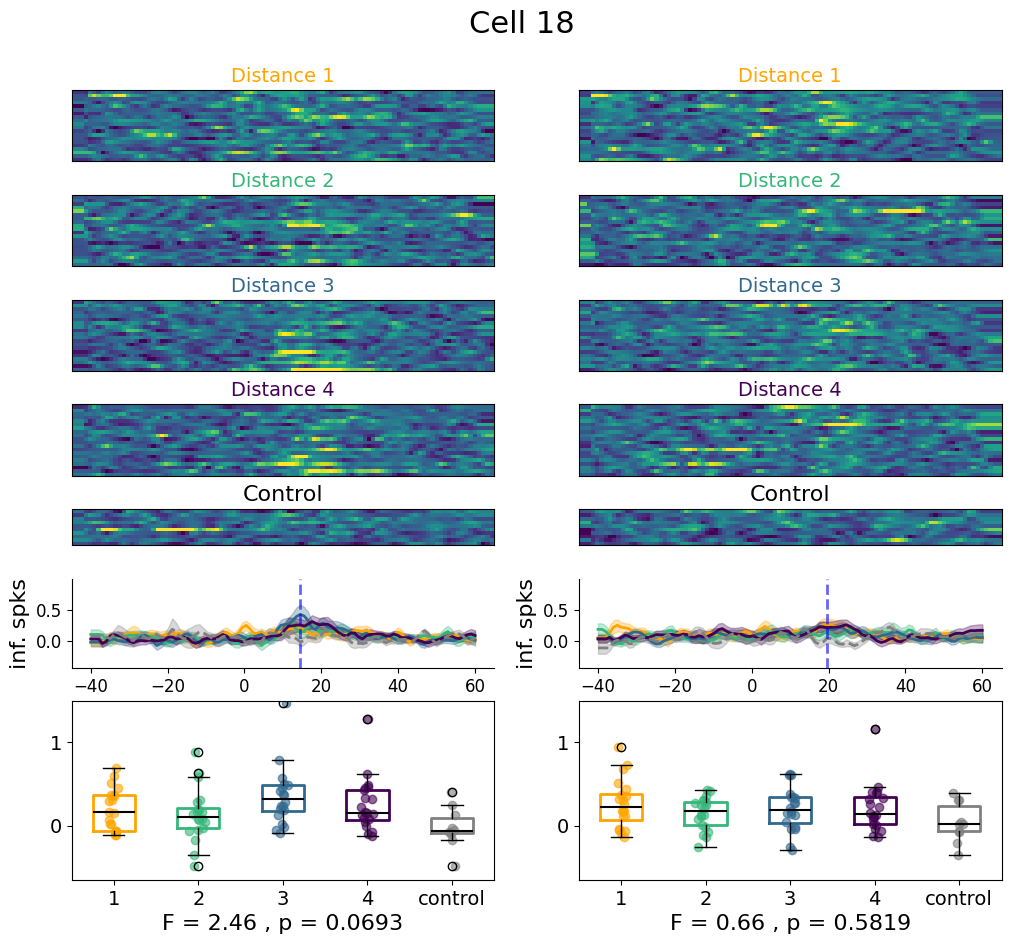

In [524]:
plot_trials_ordered_2(D, cell = 18)

1.1115488765595634
46.25


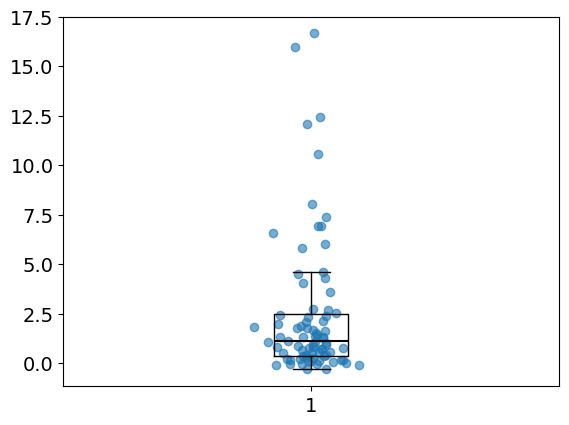

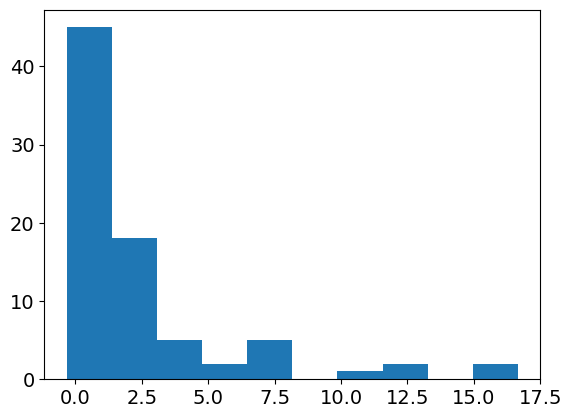

In [330]:
from scipy.stats import skew
cell = 115
all_traces = D.get_all_traces(cell, distance = [1, 2 ,3 , 4], mean_trace = False, block = 'one eye')
all_traces_mean = np.mean(all_traces, axis=0)

max_index = np.argmax(all_traces_mean)
receptive_pos = D.angle_range[max_index]
# get values at the receptive pos for all the traces
values = []
for trace in all_traces:
    values.append(trace[max_index])
    
plt.figure()
plt.boxplot(values, medianprops=dict(color="black", linewidth=1.5), showfliers=False)
x = np.random.normal(1, 0.04, len(values))
plt.scatter(x, values, alpha=0.6)

plt.figure()
plt.hist(values)

print(np.median(values))
# count values that are lesser than 0.5
count = 0
for value in values:
    if value < 1:
        count += 1
print(100* count/len(values))

# Get cells on the map

In [491]:
suite2p_dir = r'D:/data-distance-coding-project/processed-data' + '/' + str(imaging_filenames[0]) + '/suite2p/plane0'
stat = np.load(suite2p_dir + '/stat.npy', allow_pickle=True)
ops = np.load(suite2p_dir + '/ops.npy', allow_pickle=True).item()

In [440]:
np.where(D.suite2p_id==213)[0]

array([212], dtype=int64)

Text(0, 0.5, 'Angle (degrees)')

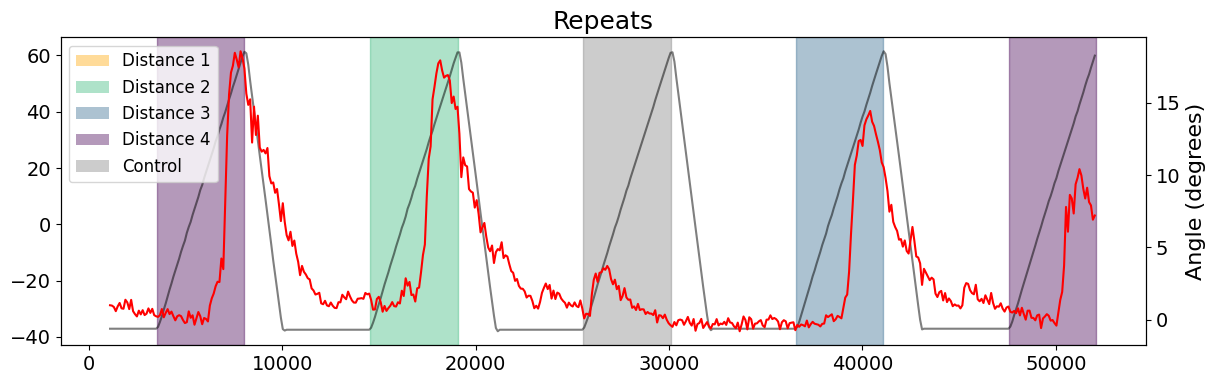

In [441]:
# import Patch
from matplotlib.patches import Patch
colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']

repeats = np.arange(0, 5)
cell = 212

fig, ax1 = plt.subplots(figsize=(14, 4))
plt.title('Repeats')

for n_trial in repeats:
    start = int(D.leg_1_start[n_trial])
    end = int(D.leg_1_end[n_trial])
    

    distance = D.distance_mat[n_trial]

    ax1.axvspan(D.leg_1_start[n_trial] + 2500, D.leg_1_end[n_trial], color=colors[distance - 1], alpha=0.4,
                label='Distance ' + str(distance))

start = int(D.leg_1_start[repeats[0]])
end = int(D.leg_1_end[repeats[-1]])

all_trial_time = D.frames_time[(D.frames_time > start) & (D.frames_time < end)]
trace_frames = (D.frames_time > start) & (D.frames_time < end)
all_trial_angle = D.angle[(D.frames_time > start) & (D.frames_time < end)]

cell_response = D.dFF[cell, trace_frames]

ax1.plot(all_trial_time, all_trial_angle, color='black', alpha = 0.5)
ax2 = ax1.twinx()
ax2.plot(all_trial_time, cell_response, color='red')

legend_elements = [Patch(facecolor=colors[0], alpha=0.4, label='Distance 1'),
                   Patch(facecolor=colors[1], alpha=0.4, label='Distance 2'),
                   Patch(facecolor=colors[2], alpha=0.4, label='Distance 3'),
                   Patch(facecolor=colors[3], alpha=0.4, label='Distance 4'),
                   Patch(facecolor=colors[4], alpha=0.4, label='Control')
                   ]
# add labels
plt.legend(handles=legend_elements)
plt.xlabel('Time (ms)')
plt.ylabel('Angle (degrees)')

In [444]:
print(D.suite2p_id)

[   0    1    2    3    4    5    6    7    8    9   10   11   12   13
   14   15   16   17   18   19   20   21   22   23   24   25   26   27
   28   29   30   31   32   33   34   35   36   37   38   39   40   41
   42   43   44   45   46   47   48   49   50   51   52   53   54   55
   56   57   58   59   60   61   62   63   64   65   66   67   68   69
   70   71   72   73   74   75   76   77   78   79   80   81   82   83
   84   85   86   87   88   89   90   91   92   93   94   95   96   97
   98   99  100  101  102  103  104  105  106  107  108  109  110  111
  112  113  114  115  116  117  118  119  120  121  122  123  124  125
  126  127  128  129  130  131  132  133  134  135  136  137  138  139
  140  141  142  143  144  145  146  147  148  149  150  151  152  153
  154  155  156  157  158  159  160  161  162  163  164  165  166  167
  168  169  170  171  172  173  174  175  176  177  178  179  180  181
  182  183  184  185  186  187  188  189  190  191  192  193  194  195
  196 

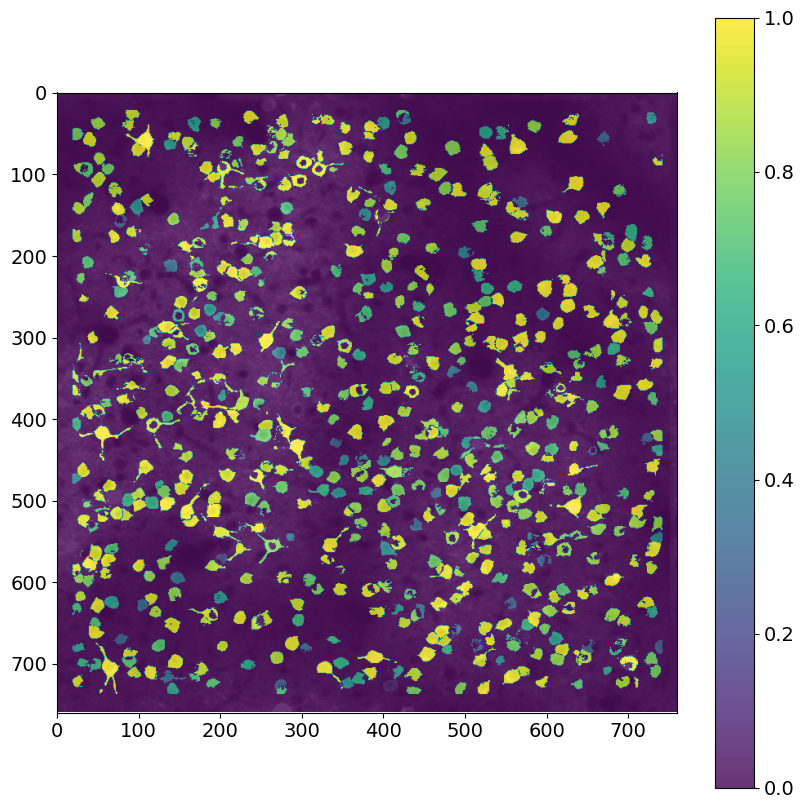

In [459]:
im = np.zeros((ops['Ly'], ops['Lx']))

for cell in order_reliability:
    suite2p_cell = D.suite2p_id[cell]
    ypix = stat[suite2p_cell]['ypix'][~stat[suite2p_cell]['overlap']]
    xpix = stat[suite2p_cell]['xpix'][~stat[suite2p_cell]['overlap']]
    im[ypix,xpix] = np.maximum(D.stats['reliability_one_eye'][cell], D.stats['reliability_two_eye'][cell])
    
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.8, cmap = 'grey', vmin=vmin, vmax=vmax)
plt.imshow(im, alpha = 0.8, vmin=0, vmax=1)
plt.colorbar()
plt.show()

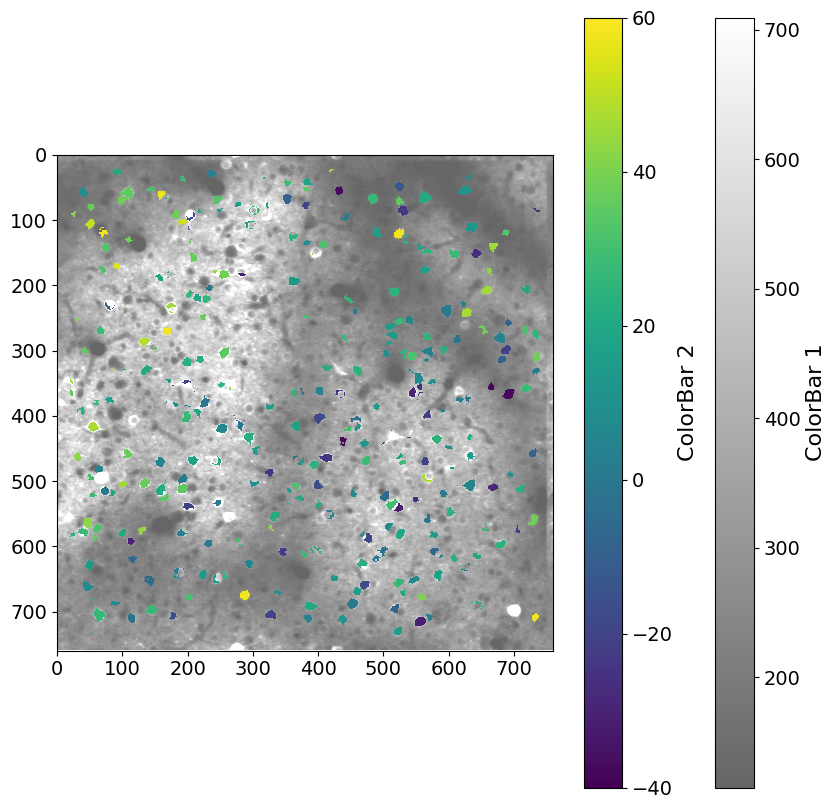

In [475]:
im = np.zeros((ops['Ly'], ops['Lx']))

for cell in order_reliability:
    
    if D.stats['is_reliable_one_eye'][cell] or D.stats['is_reliable_two_eye'][cell]:
        suite2p_cell = D.suite2p_id[cell]
        rf = D.angle_range[D.compute_receptive_field(cell)]
        ypix = stat[suite2p_cell]['ypix'][~stat[suite2p_cell]['overlap']]
        xpix = stat[suite2p_cell]['xpix'][~stat[suite2p_cell]['overlap']]
        im[ypix,xpix] = rf
    else:
        continue
    
# where image is 0 put it to nan
im[im==0] = np.nan
    
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

fig, ax1 = plt.subplots(figsize=(10, 10))

img1 = ax1.imshow(ops['refImg'], cmap = 'gray', alpha=0.6, vmin=vmin, vmax=vmax)
img2 = ax1.imshow(im, cmap = 'viridis', alpha = 1, vmin=-40, vmax=60)

bar1 = plt.colorbar(img1)
bar2.set_label('ColorBar 2')

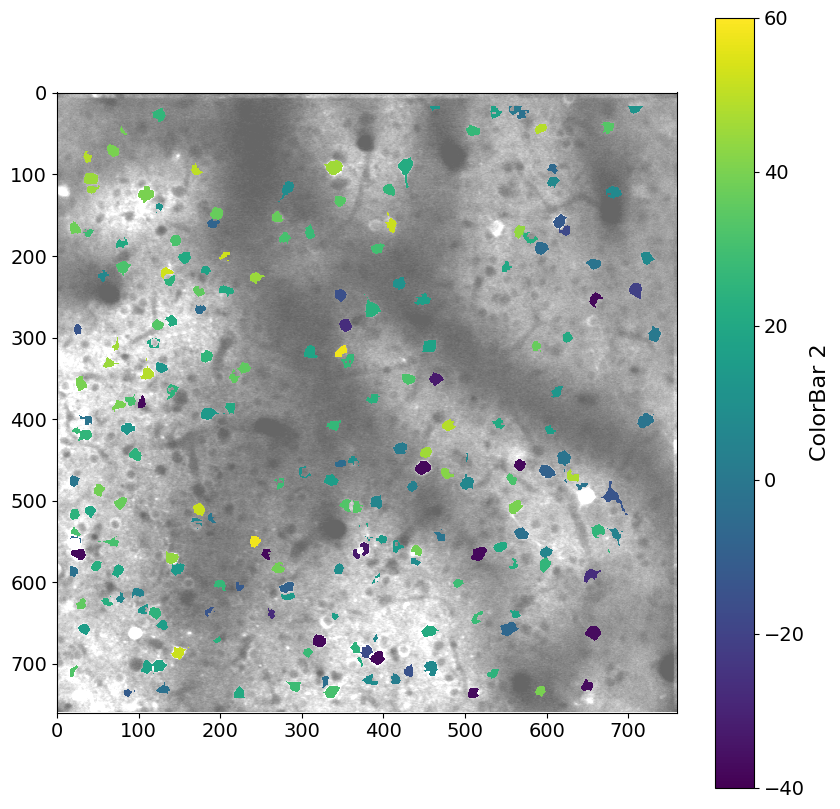

In [492]:
im = np.zeros((ops['Ly'], ops['Lx']))

for cell in order_reliability:
    
    if D.stats['is_reliable_one_eye'][cell] or D.stats['is_reliable_two_eye'][cell]:
        suite2p_cell = D.suite2p_id[cell]
        rf = D.angle_range[D.compute_receptive_field(cell)]
        ypix = stat[suite2p_cell]['ypix'][~stat[suite2p_cell]['overlap']]
        xpix = stat[suite2p_cell]['xpix'][~stat[suite2p_cell]['overlap']]
        im[ypix,xpix] = rf
    else:
        continue
    
# where image is 0 put it to nan
im[im==0] = np.nan
    
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

fig, ax1 = plt.subplots(figsize=(10, 10))

img1 = ax1.imshow(ops['refImg'], cmap = 'gray', alpha=0.6, vmin=vmin, vmax=vmax)
img2 = ax1.imshow(im, cmap = 'viridis', alpha = 1, vmin=-40, vmax=60)

bar2 = plt.colorbar(img2)
bar2.set_label('ColorBar 2')

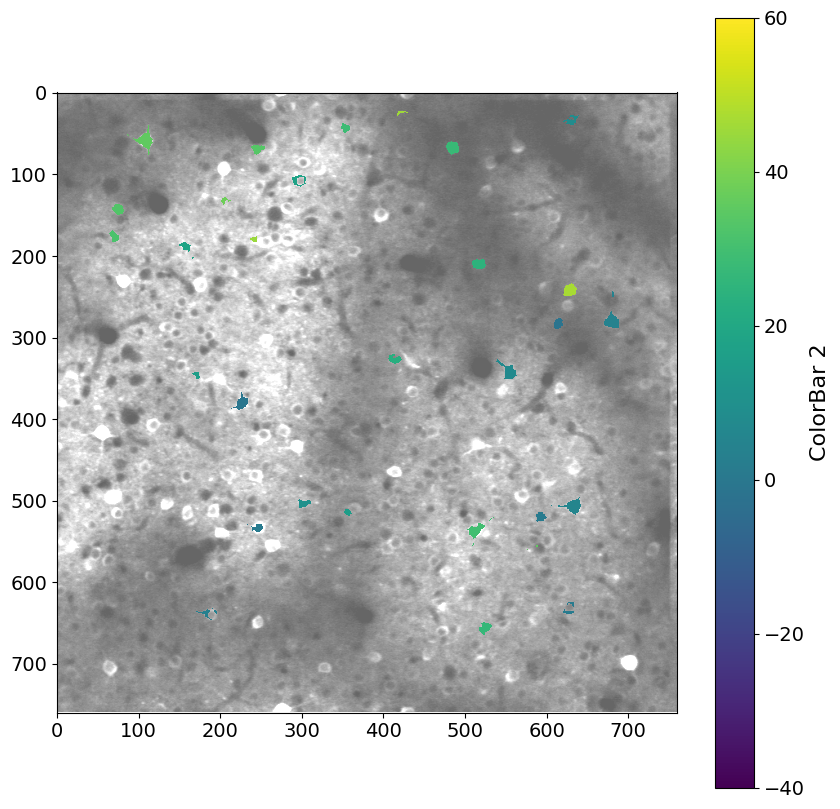

In [477]:
im = np.zeros((ops['Ly'], ops['Lx']))

for cell in order_reliability:
    
    if D.stats['is_modulated_two_eye'][cell]:
        suite2p_cell = D.suite2p_id[cell]
        rf = D.angle_range[D.compute_receptive_field(cell)]
        ypix = stat[suite2p_cell]['ypix'][~stat[suite2p_cell]['overlap']]
        xpix = stat[suite2p_cell]['xpix'][~stat[suite2p_cell]['overlap']]
        im[ypix,xpix] = rf
    else:
        continue
    
# where image is 0 put it to nan
im[im==0] = np.nan
    
mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

fig, ax1 = plt.subplots(figsize=(10, 10))

img1 = ax1.imshow(ops['refImg'], cmap = 'gray', alpha=0.6, vmin=vmin, vmax=vmax)
img2 = ax1.imshow(im, cmap = 'viridis', alpha = 1, vmin=-40, vmax=60)

bar2 = plt.colorbar(img2)
bar2.set_label('ColorBar 2')

In [528]:
import pickle
print(imaging_filenames[0])

saving_dir = data_dir + '/' + str(imaging_filenames[0])
filename = imaging_filenames[0] + '_distance.pickle'

"""Save class as a pickle file."""
with open(os.path.join(saving_dir, filename), 'wb') as f:
    pickle.dump(D, f)

# results_directories.append(data_dir + '/' + str(imaging_filename)
# 
# with open(filename, 'rb') as f:
#     G = pickle.load(f)
#     


240802_SAM024


In [529]:
with open(os.path.join(saving_dir, filename), 'rb') as f:
    G = pickle.load(f)

In [13]:
D.save_session()

In [554]:
D = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='dFF')
    
D.one_eye = np.array([np.arange(0, 45, 1), np.arange(90, 135, 1)])
D.two_eye = np.array([np.arange(45, 90, 1), np.arange(135, 180, 1)])

imaging_dir = os.path.join(data_dir, imaging_filenames[0])

is_reliable_one, reliability_one = D.compute_reliability_all_cells(block='one eye', n_iterations = 10)
print('Reliability one eye done')
is_reliable_two, reliability_two = D.compute_reliability_all_cells(block='two eye', n_iterations = 10)
print('Reliability two eye done')

D.compute_distance_modulation_all_cells(block='one eye')
D.compute_distance_modulation_all_cells(block='two eye')

D.save_session()

 Cell 696Reliability one eye done
 Cell 696Reliability two eye done


 Cell 695

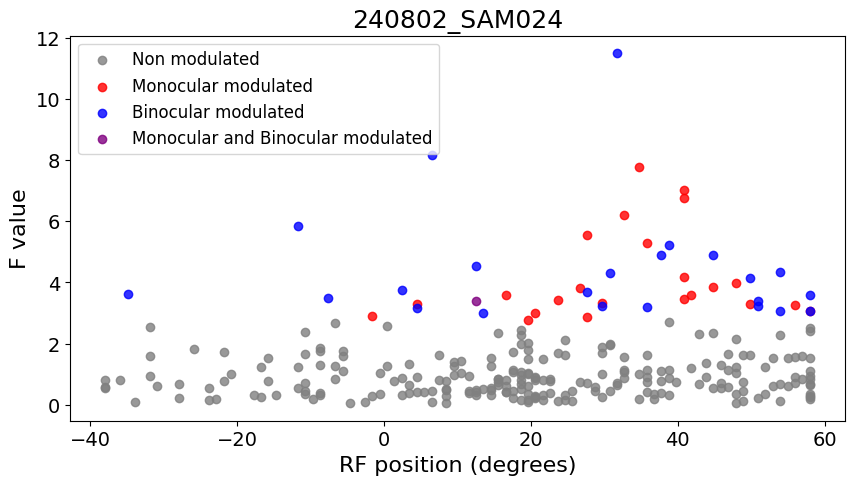

In [556]:
D.compute_distance_modulation_all_cells(block='one eye')
D.compute_distance_modulation_all_cells(block='two eye')
plot_RF_vs_modulation(D)

False
0.6607669305185304
0.48319160346744194


(array([ 1.,  1.,  1.,  3.,  4.,  6.,  3., 12., 11., 15.,  8.,  8.,  9.,
         6.,  4.,  2.,  3.,  0.,  2.,  1.]),
 array([-0.40031172, -0.35613655, -0.31196139, -0.26778622, -0.22361106,
        -0.17943589, -0.13526072, -0.09108556, -0.04691039, -0.00273522,
         0.04143994,  0.08561511,  0.12979027,  0.17396544,  0.21814061,
         0.26231577,  0.30649094,  0.3506661 ,  0.39484127,  0.43901644,
         0.4831916 ]),
 <BarContainer object of 20 artists>)

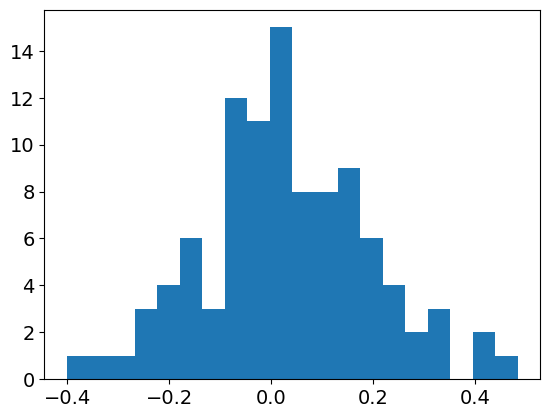

In [567]:
is_reliable, reliability, corr_shifted = D.compute_reliability(n_iterations = 100, cell = 407, block='two eye')
print(is_reliable)
print(reliability)
print(np.max(corr_shifted))
plt.figure()
plt.hist(corr_shifted, bins=20)

In [568]:
m

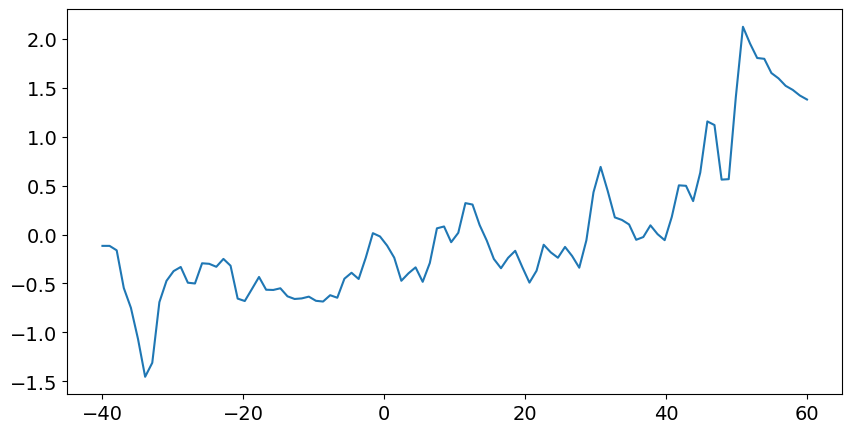

In [618]:
# transform mean_trace to zscore
cell = 673
distance_trace = []
for distance in range(1, 5):
    trace, _ = D.get_all_traces(cell = cell, mean_trace=True, distance = [distance], block='two eye')
    distance_trace.append(trace)

# collapse distance_trace into one dimension
distance_trace = np.array(distance_trace)
distance_trace = distance_trace.flatten()

pop_mean = np.mean(distance_trace)
pop_std = np.std(distance_trace)

mean_trace, std_distance = D.get_all_traces(cell = cell, mean_trace=True, distance = [1, 2, 3, 4], block='two eye')
z_trace = (mean_trace - pop_mean)/pop_std

plt.figure(figsize = (10, 5))
plt.plot(D.angle_range, z_trace)

In [561]:
print(is_reliable)
print(reliability)
print(corr_shifted)

True
0.7996087219266279
[-0.25708724863821014, -0.003884239493495527, -0.21280507137734006, -0.22124580635875485, 0.06314169563737808, 0.15531777587766726, 0.20402097216568799, -0.09822716400010909, 0.03340186270820178, 0.05137383085552701, -0.01591565646123926, 0.11789051050732749, -0.14150223253135824, 0.2990435139081548, -0.03515129745682056, 0.123196240875596, 0.03075658754009626, 0.16283532837348197, -0.22473562591030288, 0.014621823578027847, -0.11647993123383489, 0.13469384349082147, -0.020344148225974253, 0.10087958413684384, 0.05135080001471749, 0.025359499295278136, -0.29279190354741413, 0.19288082736403886, -0.4295527040148662, 0.3137611102459049, -0.2243826725697118, -0.05610112133132705, 0.22751541714439064, 0.03807628493305115, -0.1283775617604953, 0.22606659978494884, -0.3533058978311623, -0.33000677721926863, 0.10976907010216617, -0.05348658187575478, -0.09821543175968339, -0.38327290469778386, 0.03197782875510127, -0.42043355080808775, -0.18009750053905427, -0.10863466